# HW 8, Problem 4: Comparison and interpretation

Both models, with the truth, observations, $H$, $R$, $D$, and prior saved in Problem 1 (`data/hw8_twin_*.npz`). The EKF runs of Problem 2 and the EnKF runs of Problem 3 are repeated here with identical settings and seeds. Both filters are deterministic given their inputs and seeds, so the results are the same as in Problems 2 and 3 (bitwise on the machine that ran them, otherwise up to floating-point roundoff, which the chaotic dynamics amplify); the runtimes in this notebook are measured here.

## Diagnostics

With the fixed scales $D$ from Problem 1 and $n$ the state dimension,
$$\mathrm{RMSE}_k = \sqrt{\tfrac1n\big\lVert D^{-1}(m_k^a - x_k^\dagger)\big\rVert_2^2}, \qquad \mathrm{Spread}_k = \sqrt{\tfrac1n \operatorname{tr}\big(D^{-1}P_k^aD^{-T}\big)},$$
with $\bar x_k^a$, $P_{k,e}^a$ in place of $m_k^a$, $P_k^a$ for the EnKF and $m_k^a$ replaced by the free forecast for its RMSE (no spread). Both are computed at the observation times after each analysis, $k = 1, \dots, L$ (`hw8.scaled_rmse_spread`). Summaries: the time-aggregated error $\sqrt{L^{-1}\sum_{k=1}^L \mathrm{RMSE}_k^2}$, the final RMSE ($k = L$), and the mean spread $L^{-1}\sum_{k=1}^L \mathrm{Spread}_k$.

## Runtime

Wall time of the whole cycle, best of 3 identical runs:

* **EKF:** forecasts of the mean, the variational integrations for $\mathbf M_{k-1}$ (Jacobian evaluation), and the analyses.
* **EnKF:** forecasts of all members (one stacked `solve_ivp` call per window), the analyses, and recomputing the ensemble mean and covariance.
* **Free forecast:** propagation of $m_0^a$ over $[0, T]$ only.

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Markdown, display

from da_models import hw8
from da_models.assimilation import flatten, simulate_truth
from da_models.ekf import run_ekf
from da_models.enkf import draw_initial_ensemble, run_enkf

DATA_DIR = Path("../data")   # adjust if running in Colab
NAMES = ("l96", "l96_2layer")
ENSEMBLE_SIZES = hw8.ENSEMBLE_SIZES   # (50, 200)
REPLICATES = hw8.REPLICATES           # (0, 1, 2)
REPEATS = 3                           # timing: best of REPEATS identical runs

models = {name: hw8.load_model(name, DATA_DIR) for name in NAMES}
twins = {name: hw8.load_twin(name, DATA_DIR) for name in NAMES}
L, DT = hw8.L, hw8.DT_OBS
t_an = DT * np.arange(L + 1)              # t_0, ..., t_L
t_obs = t_an[1:]                          # t_1, ..., t_L

np.set_printoptions(precision=4, suppress=True, linewidth=110)
C = dict(truth="#0b0b0b", free="#8c8a85", obs="#eb6834",
         ekf="#2a78d6", enkf50="#1baf7a", enkf200="#8e44ad")
plt.rcParams.update({
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 110,
})

def time_avg_rmse(rmse):
    # sqrt( L^{-1} sum_{k=1}^{L} RMSE_k^2 ); rmse[0] is the initial time and is excluded
    return np.sqrt(np.mean(rmse[1:] ** 2))

def summary(o):
    # time-aggregated RMSE, final RMSE, mean spread (k = 1..L), runtime
    return dict(rmse=time_avg_rmse(o["rmse"]), final=o["rmse"][-1],
                spread=np.nan if o.get("spread") is None else o["spread"][1:].mean(),
                runtime=o["wall_time"])

## Runs

Free forecast (propagation of $m_0^a$; checked against the saved Problem 1 free forecast to roundoff), EKF, and EnKF with $N_e = 50, 200$ and replicates $r = 0, 1, 2$ (seeds `default_rng([513, 1, model, Ne, r])` for the initial members and `default_rng([513, 2, model, Ne, r])` for the perturbations, as in Problem 3).

In [2]:
def best_of(fn, repeats=REPEATS):
    # run fn() `repeats` times (identical results) and keep the fastest
    best = None
    for _ in range(repeats):
        out = fn()
        if best is None or out["wall_time"] < best["wall_time"]:
            best = out
    return best

def free_forecast(mdl):
    def fn():
        tic = time.perf_counter()
        seg = simulate_truth(mdl["propagate"], mdl["m0"], L)
        return dict(segments=seg, x=np.vstack([mdl["m0"], seg[:, -1]]), wall_time=time.perf_counter() - tic)
    return best_of(fn)

def ekf_run(mdl, Y, maps=None):
    maps = maps or mdl
    return best_of(lambda: run_ekf(maps["propagate"], maps["flow_jacobian"], mdl["m0"], mdl["P0"],
                                   Y, mdl["H"], mdl["R"]))

def enkf_run(mdl, Y, Ne, r, maps=None):
    maps = maps or mdl
    def fn():
        E0 = draw_initial_ensemble(mdl["m0"], mdl["P0"], Ne, hw8.rng_init(mdl["name"], Ne, r))
        return run_enkf(maps["propagate_ens"], E0, Y, mdl["H"], mdl["R"], hw8.rng_pert(mdl["name"], Ne, r))
    return best_of(fn)

free, ekf, enkf = {}, {}, {}
for name, mdl in models.items():
    tw = twins[name]
    f = free_forecast(mdl)
    # not bitwise: last-bit differences between machines/library builds are amplified by the
    # chaotic flow (about 1e-7 by t = 10 in the one-layer model), so compare in units of D
    dev = np.max(np.abs(f["x"] - tw["x_free"]) / mdl["D"])
    assert dev < 1e-5, f"free forecast differs from the saved one (max scaled difference {dev:.1e})"
    f["rmse"], _ = hw8.scaled_rmse_spread(f["x"], tw["x_true"], mdl["D"])
    free[name] = f

    o = ekf_run(mdl, tw["Y"])
    o["mean_a"], o["cov_a"] = o["m_a"], o["P_a"]          # common names for plotting
    o["rmse"], o["spread"] = hw8.scaled_rmse_spread(o["m_a"], tw["x_true"], mdl["D"], o["P_a"])
    ekf[name] = o

    for Ne in ENSEMBLE_SIZES:
        for r in REPLICATES:
            o = enkf_run(mdl, tw["Y"], Ne, r)
            o["rmse"], o["spread"] = hw8.scaled_rmse_spread(o["mean_a"], tw["x_true"], mdl["D"], o["cov_a"])
            enkf[(name, Ne, r)] = o
    print(f"{mdl['title']}: free forecast matches the saved Problem 1 run (max scaled difference {dev:.1e}); "
          f"EKF {'completed' if ekf[name]['failed_at'] is None else 'FAILED'}; "
          f"EnKF failed runs: {sum(enkf[(name, Ne, r)]['failed_at'] is not None for Ne in ENSEMBLE_SIZES for r in REPLICATES)} of "
          f"{len(ENSEMBLE_SIZES) * len(REPLICATES)}")

# representative EnKF run for each size: the replicate with the median time-aggregated RMSE
rep = {}
for name in NAMES:
    for Ne in ENSEMBLE_SIZES:
        done = [r for r in REPLICATES if enkf[(name, Ne, r)]["failed_at"] is None]
        scores = [time_avg_rmse(enkf[(name, Ne, r)]["rmse"]) for r in done]
        rep[(name, Ne)] = done[int(np.argsort(scores)[len(scores) // 2])]
        print(f"{models[name]['title']}, Ne = {Ne}: representative replicate r = {rep[(name, Ne)]} "
              f"(time-aggregated RMSE {', '.join(f'r={r}: {s:.3f}' for r, s in zip(done, scores))})")

One-layer Lorenz-96: free forecast matches the saved Problem 1 run; EKF completed; EnKF failed runs: 0 of 6


Two-layer Lorenz-96 (K = 10, J = 2): free forecast matches the saved Problem 1 run; EKF completed; EnKF failed runs: 0 of 6
One-layer Lorenz-96, Ne = 50: representative replicate r = 2 (time-aggregated RMSE r=0: 0.371, r=1: 0.175, r=2: 0.185)
One-layer Lorenz-96, Ne = 200: representative replicate r = 1 (time-aggregated RMSE r=0: 0.109, r=1: 0.110, r=2: 0.115)
Two-layer Lorenz-96 (K = 10, J = 2), Ne = 50: representative replicate r = 0 (time-aggregated RMSE r=0: 0.057, r=1: 0.062, r=2: 0.051)
Two-layer Lorenz-96 (K = 10, J = 2), Ne = 200: representative replicate r = 0 (time-aggregated RMSE r=0: 0.054, r=1: 0.052, r=2: 0.055)


## (a) Time series and RMSE/spread

One column per filter: EKF, and the representative EnKF run (median time-aggregated RMSE of the three replicates) for each ensemble size. Rows: an observed coordinate, hidden coordinates, then the scaled RMSE (solid) and spread (dashed) at $t_1, \dots, t_L$ for the same run. The time series are in the model's own units (Lorenz–96 variables are nondimensional), and they include the forecast between observation times, so the vertical strokes are the analysis updates. Shaded bands are the filter mean $\pm 2$ marginal standard deviations: EKF $\sqrt{\operatorname{diag}(\Phi(t)P^a\Phi(t)^T)}$ inside each window, EnKF the ensemble standard deviation. These bands are uncertainty diagnostics, not a guarantee of 95% coverage in a nonlinear system.

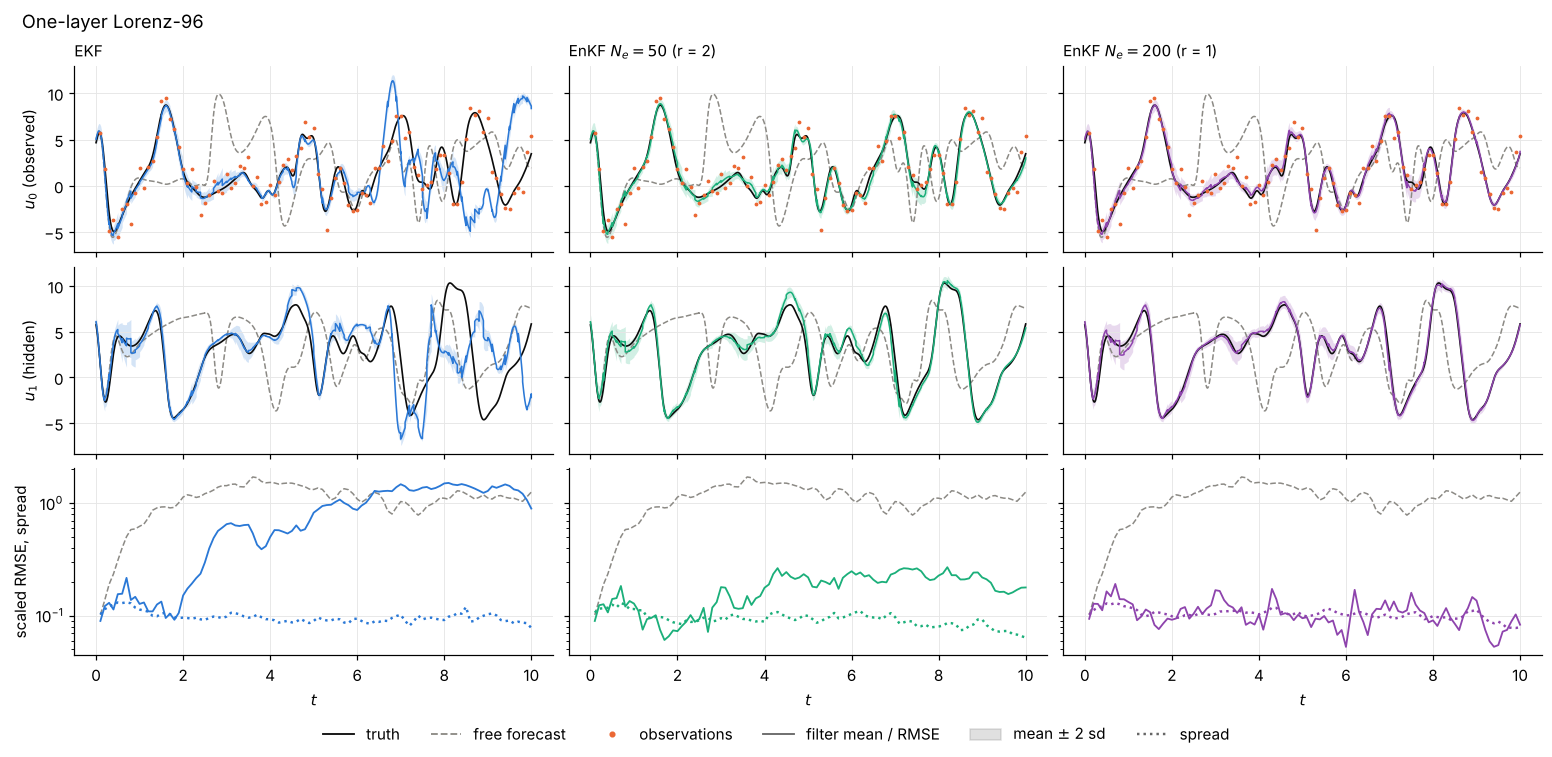

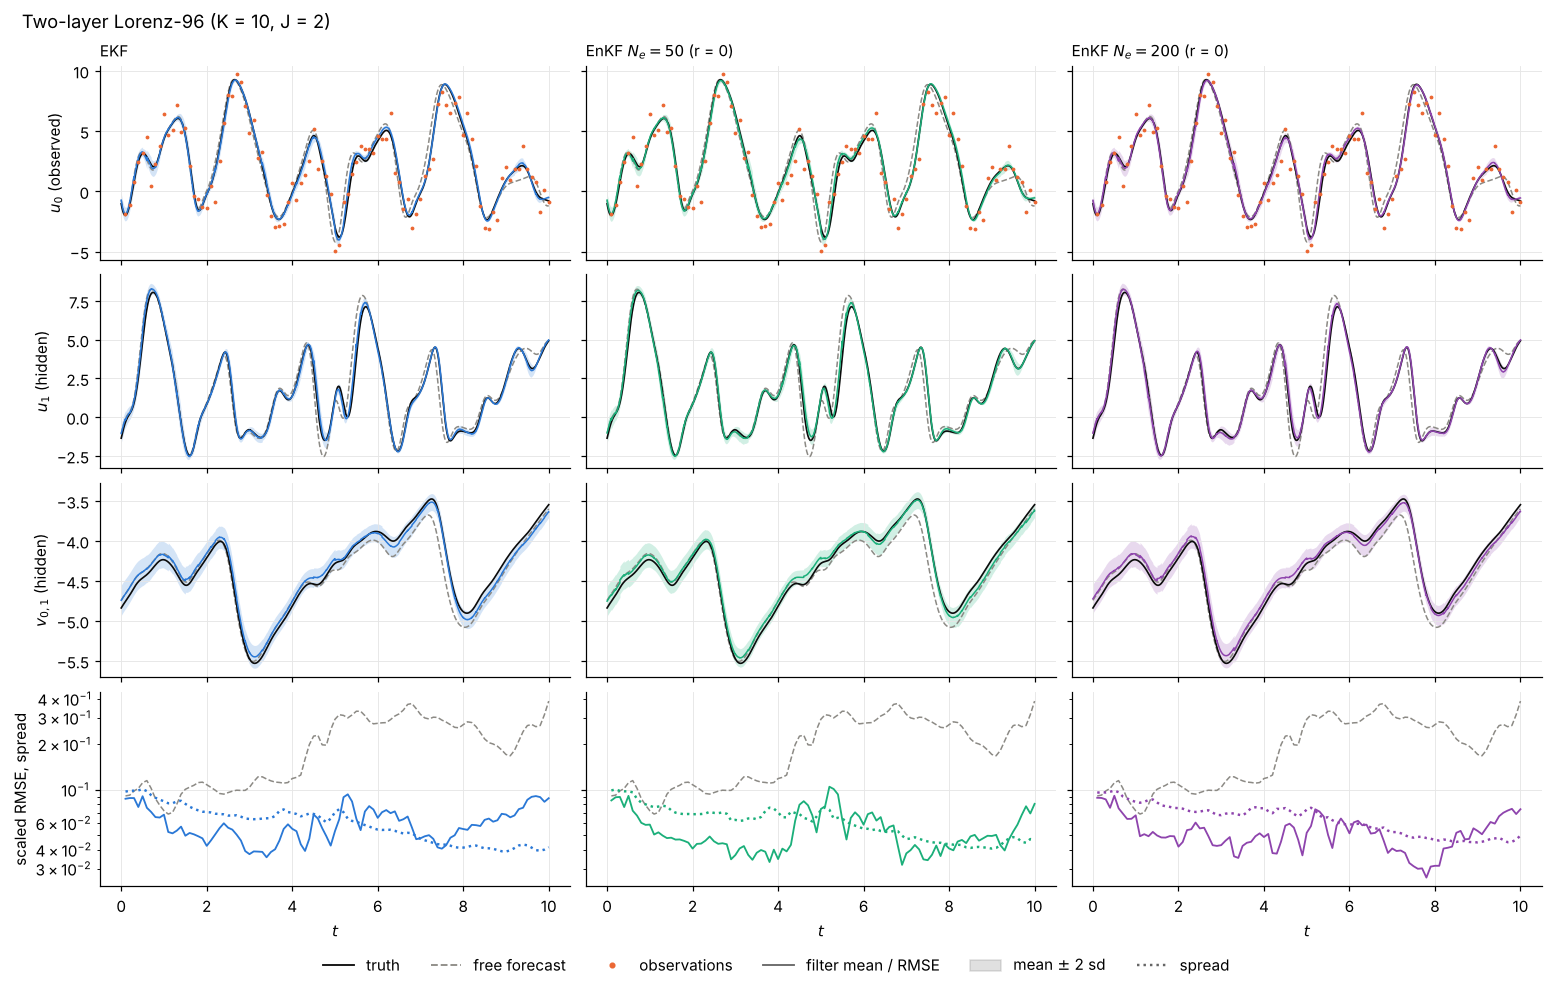

In [3]:
ROWS = {"l96": ["u0", "u1"], "l96_2layer": ["u0", "u1", "v0,1"]}   # observed first, then hidden

def filter_runs(name):
    return [("EKF", ekf[name], C["ekf"])] + [
        (f"EnKF $N_e = {Ne}$ (r = {rep[(name, Ne)]})", enkf[(name, Ne, rep[(name, Ne)])], C[f"enkf{Ne}"])
        for Ne in ENSEMBLE_SIZES]

def plot_model(name):
    mdl, tw, fr = models[name], twins[name], free[name]
    rows = ROWS[name]
    runs = filter_runs(name)
    fig, axes = plt.subplots(len(rows) + 1, len(runs), figsize=(14, 2.1 * len(rows) + 2.6),
                             sharex=True, sharey="row", constrained_layout=True)
    t_tr, X_tr = flatten(tw["truth_segments"], DT)
    t_fr, X_fr = flatten(fr["segments"], DT)
    for j, (label, o, color) in enumerate(runs):
        t_m, X_m = flatten(o["seg_mean"], DT, o["mean_a"][-1])
        _, S_m = flatten(o["seg_std"], DT, np.sqrt(np.diag(o["cov_a"][-1])))
        for i, lab in enumerate(rows):
            ax, c = axes[i, j], mdl["labels"].index(lab)
            ax.fill_between(t_m, X_m[:, c] - 2 * S_m[:, c], X_m[:, c] + 2 * S_m[:, c],
                            color=color, alpha=0.2, lw=0)
            ax.plot(t_fr, X_fr[:, c], color=C["free"], ls="--", lw=1)
            ax.plot(t_tr, X_tr[:, c], color=C["truth"], lw=1.1)
            ax.plot(t_m, X_m[:, c], color=color, lw=1)
            if c in mdl["observed"]:
                ax.plot(t_obs, tw["Y"][:, mdl["observed"].index(c)], ".", color=C["obs"], ms=3)
            if j == 0:
                sym = f"v_{{{lab[1:]}}}" if lab.startswith("v") else f"u_{{{lab[1:]}}}"
                ax.set_ylabel(f"${sym}$ ({'observed' if c in mdl['observed'] else 'hidden'})")
        ax = axes[-1, j]
        ax.semilogy(t_obs, fr["rmse"][1:], color=C["free"], ls="--", lw=1)
        ax.semilogy(t_obs, o["rmse"][1:], color=color)
        ax.semilogy(t_obs, o["spread"][1:], color=color, ls=":", lw=1.6)
        ax.set_xlabel("$t$")
        axes[0, j].set_title(label, loc="left", fontsize=10)
    axes[-1, 0].set_ylabel("scaled RMSE, spread")
    handles = [Line2D([], [], color=C["truth"], label="truth"),
               Line2D([], [], color=C["free"], ls="--", label="free forecast"),
               Line2D([], [], color=C["obs"], marker=".", ls="", label="observations"),
               Line2D([], [], color="0.4", label="filter mean / RMSE"),
               Patch(color="0.4", alpha=0.2, label=r"mean $\pm$ 2 sd"),
               Line2D([], [], color="0.4", ls=":", lw=1.6, label="spread")]
    fig.legend(handles=handles, loc="outside lower center", ncol=6)
    fig.suptitle(mdl["title"], x=0.01, ha="left")
    return fig

for name in NAMES:
    plot_model(name)
plt.show()

## (b) Summary tables

EnKF entries are the mean over the three replicates with the range [min, max]. Failed runs would be listed and excluded from the mean and range (none failed). Runtime definitions are given at the top of the notebook; the EKF runtime includes the Jacobian (variational) integrations, whose share is listed separately.

In [4]:
def fmt_range(values, digits=3):
    v = np.asarray(values)
    return f"{v.mean():.{digits}f} [{v.min():.{digits}f}, {v.max():.{digits}f}]"

for name, mdl in models.items():
    rows = []
    s = summary(ekf[name])
    status = "0 of 1" if ekf[name]["failed_at"] is None else f"1 of 1 (k = {ekf[name]['failed_at']})"
    rows.append(f"| EKF | {s['rmse']:.3f} | {s['final']:.3f} | {s['spread']:.3f} | "
                f"{s['runtime']:.2f} (Jacobian {ekf[name]['jacobian_time']:.2f}) | {status} |")
    for Ne in ENSEMBLE_SIZES:
        reps = [enkf[(name, Ne, r)] for r in REPLICATES]
        done = [o for o in reps if o["failed_at"] is None]
        failed = [f"r = {r} (k = {o['failed_at']})" for r, o in zip(REPLICATES, reps) if o["failed_at"] is not None]
        ss = [summary(o) for o in done]
        rows.append(f"| EnKF, $N_e = {Ne}$ | {fmt_range([x['rmse'] for x in ss])} | "
                    f"{fmt_range([x['final'] for x in ss])} | {fmt_range([x['spread'] for x in ss])} | "
                    f"{fmt_range([x['runtime'] for x in ss], 2)} | "
                    f"{len(failed)} of {len(reps)}{': ' + ', '.join(failed) if failed else ''} |")
    rows.append(f"| Free forecast | {time_avg_rmse(free[name]['rmse']):.3f} | {free[name]['rmse'][-1]:.3f} | — | "
                f"{free[name]['wall_time']:.2f} (propagation) | — |")
    display(Markdown(
        f"**{mdl['title']}** ($n = {mdl['n']}$, $p = {mdl['H'].shape[0]}$)\n\n"
        "| Method | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs |\n"
        "|---|---|---|---|---|---|\n" + "\n".join(rows)))

**One-layer Lorenz-96** ($n = 40$, $p = 20$)

| Method | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs |
|---|---|---|---|---|---|
| EKF | 0.945 | 0.898 | 0.097 | 2.65 (Jacobian 1.77) | 0 of 1 |
| EnKF, $N_e = 50$ | 0.244 [0.175, 0.371] | 0.410 [0.178, 0.731] | 0.093 [0.093, 0.093] | 1.24 [1.21, 1.29] | 0 of 3 |
| EnKF, $N_e = 200$ | 0.111 [0.109, 0.115] | 0.082 [0.072, 0.092] | 0.104 [0.103, 0.104] | 2.43 [2.37, 2.52] | 0 of 3 |
| Free forecast | 1.155 | 1.259 | — | 0.67 (propagation) | — |

**Two-layer Lorenz-96 (K = 10, J = 2)** ($n = 30$, $p = 5$)

| Method | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Failed runs |
|---|---|---|---|---|---|
| EKF | 0.062 | 0.088 | 0.061 | 2.87 (Jacobian 2.01) | 0 of 1 |
| EnKF, $N_e = 50$ | 0.056 [0.051, 0.062] | 0.067 [0.049, 0.081] | 0.063 [0.062, 0.064] | 1.29 [1.17, 1.44] | 0 of 3 |
| EnKF, $N_e = 200$ | 0.054 [0.052, 0.055] | 0.082 [0.074, 0.092] | 0.065 [0.064, 0.066] | 2.01 [1.89, 2.23] | 0 of 3 |
| Free forecast | 0.220 | 0.388 | — | 0.78 (propagation) | — |

## (c) Observations half as frequent

* **Data.** Every second observation of the saved baseline data: $y_k$ for $k = 2, 4, \dots, 100$, i.e. $t = 0.2, 0.4, \dots, 10$ (`Y[1::2]`, since `Y[k-1]` $= y_k$), giving 50 analyses. The truth and the retained data are not regenerated.
* **Model maps.** Each forecast now covers $2\delta t = 0.2$: the same `solve_ivp` settings (RK45, `rtol = atol = 1e-9`), and the EKF's $\mathbf M_{k-1}$ is recomputed from the variational equations over the longer window (`hw8.make_maps(..., dt = 0.2, n_sub = 20)`).
* **Unchanged.** $T$, $R$, the prior, solver tolerances, and everything else. EKF, and EnKF with $N_e = 200$ and baseline replicate $r = $ `R_C` (same initial ensemble as the baseline run; its perturbation stream is the same generator, used for 50 instead of 100 analyses).
* **Comparison.** The baseline runs from above, evaluated at the same retained times $k = 2, 4, \dots, 100$. Runtimes are for the whole run over $[0, T]$: 100 forecast–analysis cycles for the baseline, 50 longer ones with every second observation.
* **Models.** The assignment asks for one model; both are run because it is inexpensive. Set `MODELS_C` to keep one.

In [5]:
MODELS_C = ("l96", "l96_2layer")
NE_C, R_C = 200, 0

half = {}
for name in MODELS_C:
    mdl, tw = models[name], twins[name]
    maps2 = hw8.make_maps(mdl["rhs"], mdl["jac"], mdl["params"], 2 * DT, 2 * hw8.N_SUB)
    Y_half = tw["Y"][1::2]
    x_ret = tw["x_true"][::2]                       # truth at k = 0, 2, ..., 100
    o_ekf = ekf_run(mdl, Y_half, maps2)
    o_ekf["mean_a"], o_ekf["cov_a"] = o_ekf["m_a"], o_ekf["P_a"]
    o_enkf = enkf_run(mdl, Y_half, NE_C, R_C, maps2)
    for o in (o_ekf, o_enkf):
        o["rmse"], o["spread"] = hw8.scaled_rmse_spread(o["mean_a"], x_ret, mdl["D"], o["cov_a"])
    half[name] = dict(maps2=maps2, ekf=o_ekf, enkf=o_enkf)

def at_retained(o):
    # baseline diagnostics at k = 0, 2, ..., 100 (row 0 is k = 0 and is excluded from summaries)
    return dict(rmse=o["rmse"][::2], spread=o["spread"][::2], wall_time=o["wall_time"])

for name in MODELS_C:
    mdl = models[name]
    pairs = [("EKF", at_retained(ekf[name]), half[name]["ekf"]),
             (f"EnKF, $N_e = {NE_C}$, r = {R_C}", at_retained(enkf[(name, NE_C, R_C)]), half[name]["enkf"])]
    rows = []
    for label, base, h in pairs:
        for tag, o in (("every observation ($\\delta t = 0.1$)", base), ("every second observation ($2\\delta t = 0.2$)", h)):
            s = summary(o)
            failed = o.get("failed_at") is not None
            rows.append(f"| {label} | {tag} | {s['rmse']:.3f} | {s['final']:.3f} | {s['spread']:.3f} | "
                        f"{s['runtime']:.2f} | {'FAILED' if failed else 'completed'} |")
    display(Markdown(
        f"**{mdl['title']}**, diagnostics at the retained times $t = 0.2, 0.4, \\dots, 10$\n\n"
        "| Filter | Observations | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Status |\n"
        "|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

**One-layer Lorenz-96**, diagnostics at the retained times $t = 0.2, 0.4, \dots, 10$

| Filter | Observations | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Status |
|---|---|---|---|---|---|---|
| EKF | every observation ($\delta t = 0.1$) | 0.947 | 0.898 | 0.097 | 2.65 | completed |
| EKF | every second observation ($2\delta t = 0.2$) | 1.012 | 1.322 | 0.132 | 2.88 | completed |
| EnKF, $N_e = 200$, r = 0 | every observation ($\delta t = 0.1$) | 0.108 | 0.072 | 0.103 | 2.37 | completed |
| EnKF, $N_e = 200$, r = 0 | every second observation ($2\delta t = 0.2$) | 0.408 | 0.362 | 0.149 | 2.14 | completed |

**Two-layer Lorenz-96 (K = 10, J = 2)**, diagnostics at the retained times $t = 0.2, 0.4, \dots, 10$

| Filter | Observations | Time-aggregated RMSE | Final RMSE | Mean spread | Runtime (s) | Status |
|---|---|---|---|---|---|---|
| EKF | every observation ($\delta t = 0.1$) | 0.062 | 0.088 | 0.061 | 2.87 | completed |
| EKF | every second observation ($2\delta t = 0.2$) | 0.088 | 0.117 | 0.077 | 2.50 | completed |
| EnKF, $N_e = 200$, r = 0 | every observation ($\delta t = 0.1$) | 0.054 | 0.074 | 0.065 | 2.23 | completed |
| EnKF, $N_e = 200$, r = 0 | every second observation ($2\delta t = 0.2$) | 0.073 | 0.092 | 0.084 | 1.65 | completed |

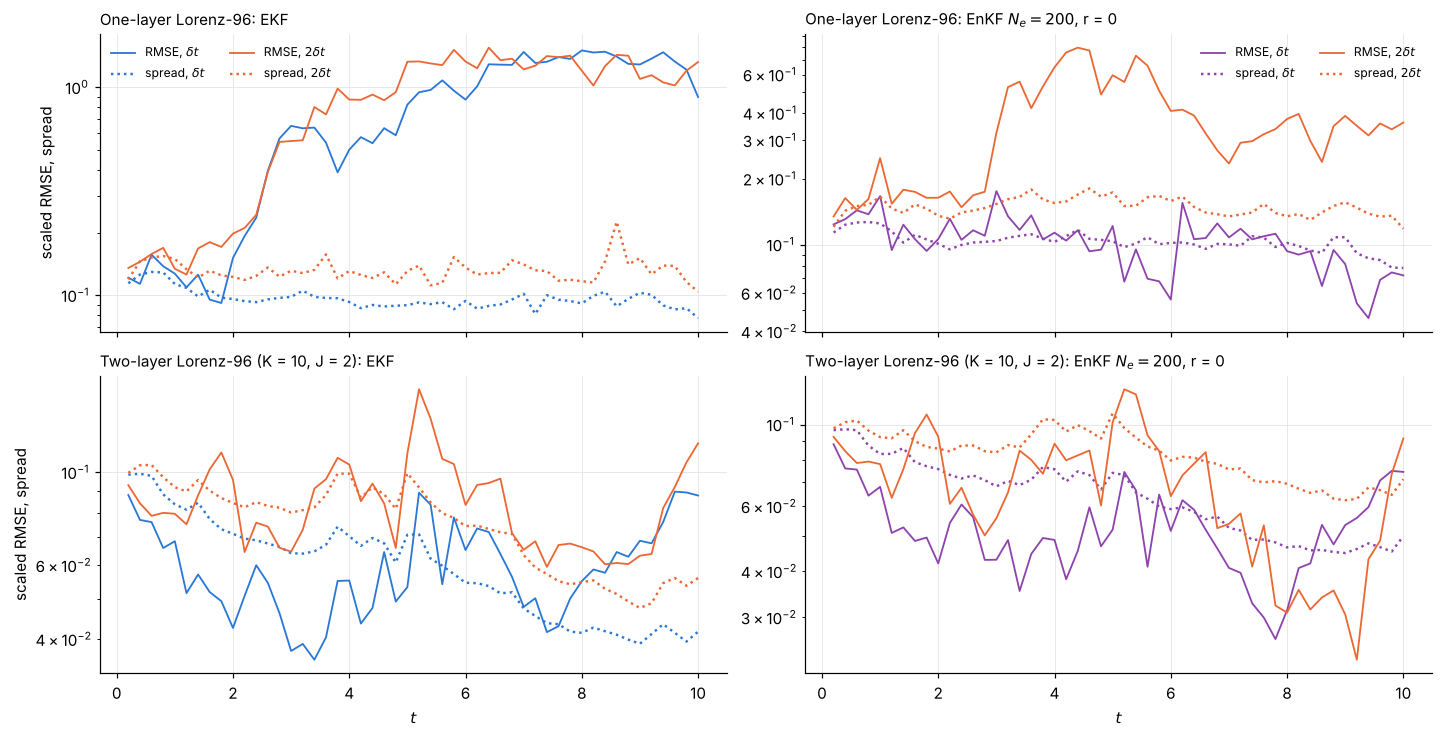

In [6]:
t_ret = 2 * DT * np.arange(1, L // 2 + 1)              # retained times t = 0.2, ..., 10
fig, axes = plt.subplots(len(MODELS_C), 2, figsize=(13, 3.3 * len(MODELS_C)), sharex=True,
                         constrained_layout=True, squeeze=False)
for i, name in enumerate(MODELS_C):
    for j, (label, base, h, color) in enumerate([
            ("EKF", ekf[name], half[name]["ekf"], C["ekf"]),
            (f"EnKF $N_e = {NE_C}$, r = {R_C}", enkf[(name, NE_C, R_C)], half[name]["enkf"], C["enkf200"])]):
        ax = axes[i, j]
        ax.semilogy(t_ret, base["rmse"][2::2], color=color, label=r"RMSE, $\delta t$")
        ax.semilogy(t_ret, base["spread"][2::2], color=color, ls=":", lw=1.6, label=r"spread, $\delta t$")
        ax.semilogy(t_ret, h["rmse"][1:], color=C["obs"], label=r"RMSE, $2\delta t$")
        ax.semilogy(t_ret, h["spread"][1:], color=C["obs"], ls=":", lw=1.6, label=r"spread, $2\delta t$")
        ax.set_title(f"{models[name]['title']}: {label}", loc="left", fontsize=10)
    axes[i, 0].set_ylabel("scaled RMSE, spread")
for ax in axes[-1]:
    ax.set_xlabel("$t$")
for ax in axes[0]:
    ax.legend(fontsize=8, ncol=2)
plt.show()

### Optional diagnostic: accuracy of the EKF's linearization over $\delta t$ and $2\delta t$

The EKF assumes $\mathcal M(x) \approx \mathcal M(m^a) + \mathbf M(x - m^a)$ for the states it considers plausible. A direct test uses the actual analysis error $e_k = x_k^\dagger - m_k^a$ of the baseline EKF: how well does $\mathbf M e_k$ predict the true difference $\mathcal M(x_k^\dagger) - \mathcal M(m_k^a)$ one forecast later? For the baseline analyses at $k = 0, 2, \dots, 98$ (the same analysis states and errors for both lengths), the relative linearization error
$$\frac{\big\lVert \mathcal M(x_k^\dagger) - \mathcal M(m_k^a) - \mathbf M e_k\big\rVert}{\big\lVert \mathcal M(x_k^\dagger) - \mathcal M(m_k^a)\big\rVert}$$
is computed with the flow map and Jacobian over $\delta t$ and over $2\delta t$. This uses no new data and changes no filter run; it isolates the effect of the forecast length at a fixed error size.

One-layer Lorenz-96: median relative linearization error 0.480 over dt, 0.864 over 2 dt;  first 10 analyses (t < 2): 0.071, 0.138


Two-layer Lorenz-96 (K = 10, J = 2): median relative linearization error 0.018 over dt, 0.029 over 2 dt;  first 10 analyses (t < 2): 0.018, 0.035


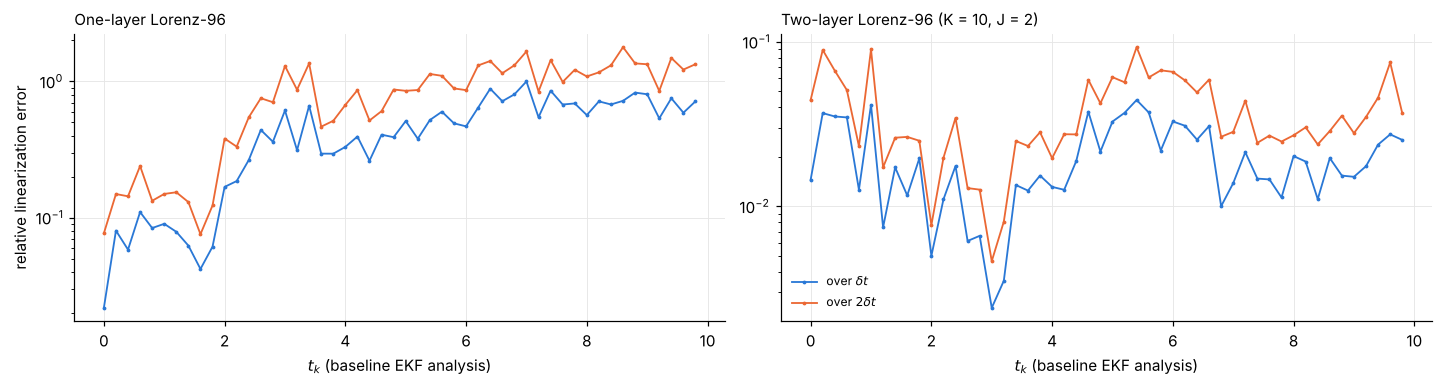

In [7]:
fig, axes = plt.subplots(1, len(MODELS_C), figsize=(13, 3.4), constrained_layout=True, squeeze=False)
for ax, name in zip(axes[0], MODELS_C):
    mdl, tw, o = models[name], twins[name], ekf[name]
    maps2 = half[name]["maps2"]
    ks = np.arange(0, L - 1, 2)                                  # k = 0, 2, ..., 98
    lin = {1: [], 2: []}
    for k in ks:
        e = tw["x_true"][k] - o["m_a"][k]
        # one window: M(x_k^dagger) is the saved truth x_{k+1}; M(m_k^a) is the EKF forecast m_{k+1}^f
        true_d = tw["x_true"][k + 1] - o["m_f"][k + 1]
        lin[1].append(np.linalg.norm(true_d - o["M"][k] @ e) / np.linalg.norm(true_d))
        # two windows: x_{k+2}^dagger, and the 2*dt flow map and Jacobian at m_k^a
        true_d2 = tw["x_true"][k + 2] - maps2["propagate"](o["m_a"][k])[-1]
        M2 = maps2["flow_jacobian"](o["m_a"][k])[-1]
        lin[2].append(np.linalg.norm(true_d2 - M2 @ e) / np.linalg.norm(true_d2))
    ax.semilogy(t_an[ks], lin[1], ".-", color=C["ekf"], ms=3, label=r"over $\delta t$")
    ax.semilogy(t_an[ks], lin[2], ".-", color=C["obs"], ms=3, label=r"over $2\delta t$")
    ax.set_title(f"{mdl['title']}", loc="left", fontsize=10)
    ax.set_xlabel("$t_k$ (baseline EKF analysis)")
    print(f"{mdl['title']}: median relative linearization error {np.median(lin[1]):.3f} over dt, "
          f"{np.median(lin[2]):.3f} over 2 dt;  first 10 analyses (t < 2): {np.median(lin[1][:10]):.3f}, "
          f"{np.median(lin[2][:10]):.3f}")
axes[0, 0].set_ylabel("relative linearization error")
axes[0, -1].legend(fontsize=8)
plt.show()

**Answer to 4(c).** *Compare the time-aggregated error, uncertainty, and runtime with the baseline values at the same retained times. Explain how a longer forecast interval affects the EKF's local linearization and the ensemble's approximation.*



## (d) Discussion

**Answer to 4(d).** *Discuss the evidence from both models: estimation of hidden variables, error versus spread, variability across ensemble seeds, cost, and failures or domain restrictions. Give a conditional recommendation for using the EKF or the EnKF in these experiments, supported by the reported results.*



## AI use (draft — edit as needed)

Claude (Anthropic) helped write and debug the code for Problem 4: the `make_maps` helper in `hw8.py` and the code cells in this notebook (figures, tables, the half-frequency runs, and the linearization diagnostic). The answers to 4(c) and 4(d) are my own.